<a href="https://colab.research.google.com/github/TRPG-masterbot/data/blob/main/%EA%B9%80%EC%9E%AC%ED%98%81_TRPG.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 1. 준비 & 설치 단계



In [1]:
# 1 준비, GPU 확인
import torch, time

print("CUDA 사용 가능:", torch.cuda.is_available())

if torch.cuda.is_available():
  print("GPU:", torch.cuda.get_device_name(0))
else:
  print("GPU를 사용할 수 없습니다.")

CUDA 사용 가능: True
GPU: NVIDIA L4


In [2]:
# 라이브러리 설치
!pip install -q transformers accelerate

# 1-1 모델 Qwen3.5-9B (테스트할땐 4B로)

In [21]:
# 1-1 모델 준비 (4B로 실행시 47초)

from transformers import AutoTokenizer, Qwen3_5ForCausalLM

model_name = "Qwen/Qwen3.5-4B"

# 토크나이저 불러오기
tokenizer = AutoTokenizer.from_pretrained(model_name)

# 언어 모델 불러오기
model = Qwen3_5ForCausalLM.from_pretrained(
    model_name,
    torch_dtype="auto",
    device_map="auto"
)

Loading weights:   0%|          | 0/426 [00:00<?, ?it/s]

In [4]:
# 1-2 모델 작동 Test. (지금은 테스트용 질문 대답)

# 모델을 평가 모드로 설정
model.eval()

# 테스트 질문 작성
messages = [
    {
        "role": "user", "content": "너의 역할은 텍스처 어드벤처 게임을 진행하는 마스터 봇이야."
    }
]

# 문자열을 토큰 ID와 텐서로 변환
inputs = tokenizer.apply_chat_template(
    messages,
    tokenize=True,
    add_generation_prompt=True,            # 모델이 답변을 시작할 위치 표시
    return_tensors="pt",                   # 결과를 PyTorch 텐서 형태로 반환
    return_dict=True,                      # 결과를 딕셔너리 형태로 반환
    enable_thinking=False                  # 추론 모드를 끄고 일반 답변을 유도
)

# 입력 텐서를 모델 장치로 이동
inputs = inputs.to(model.device)

print("입력 장치:", inputs["input_ids"].device)
print("입력 토큰 수:", inputs["input_ids"].shape[-1])      # 텐서 크기 확인

# 답변 생성
with torch.inference_mode():               # 추론 과정에서 기울기 계산을 비활성화해 메모리와 연산 부담을 줄임
  outputs = model.generate(
      **inputs,
      max_new_tokens=200,
      do_sample=False
  )

# 새로 생성된 부분만 텍스트로 변환
new_tokens = outputs[0, inputs["input_ids"].shape[-1]:]

answer = tokenizer.decode(
    new_tokens,
    skip_special_tokens=True
)

print("\n모델 답변:")
print(answer)

입력 장치: cuda:0
입력 토큰 수: 31


[transformers] `causal_conv1d_fn` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `chunk_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.
[transformers] `causal_conv1d_update` is falling back to its reference PyTorch implementation because `causal_conv1d` is not installed. This is correct but much slower; install `causal_conv1d` for the optimized kernel.
[transformers] `fused_recurrent_gated_delta_rule` is falling back to its reference PyTorch implementation because `flash-linear-attention` is not installed. This is correct but much slower; install `flash-linear-attention` for the optimized kernel.



모델 답변:
알겠습니다! 이제부터 저는 당신을 안내하는 **텍스처 어드벤처 게임의 마스터 봇**입니다. 🎮✨

이 게임은 단순한 선택지가 아니라, 당신의 선택에 따라 세계의 **텍스처**(색상, 질감, 분위기) 가 실시간으로 변하며 이야기가 전개되는 독특한 모험입니다. 당신의 결정이 더러움을 더하거나, 빛을 더하거나, 혹은 완전히 새로운 차원을 열어줄 수도 있습니다.

---

### 🌌 게임 시작: "무제 (Untitled)"

당신은 어둠이 깔린 숲의 한가운데에 서 있습니다.
주변은 **검은색과 회색의 거친 돌**로 덮여 있으며, 공기 중에는 차가운 **진흙 냄새**가撲鼻합니다. 여기서는 아무런 소리도 들리지 않습니다.

갑자기, 당신의 발밑에서 미세한 **금색의 반짝임


In [5]:
# 메모리 확인

free, total = torch.cuda.mem_get_info()
print(f"사용 가능 메모리: {free / 1024**3:.2f} GB")
print(f"최대 메모리: {total / 1024**3:.2f} GB")

사용 가능 메모리: 5.03 GB
최대 메모리: 22.03 GB


# 2. 룰북과 시나리오 PDF 텍스트로 추출하는 단계

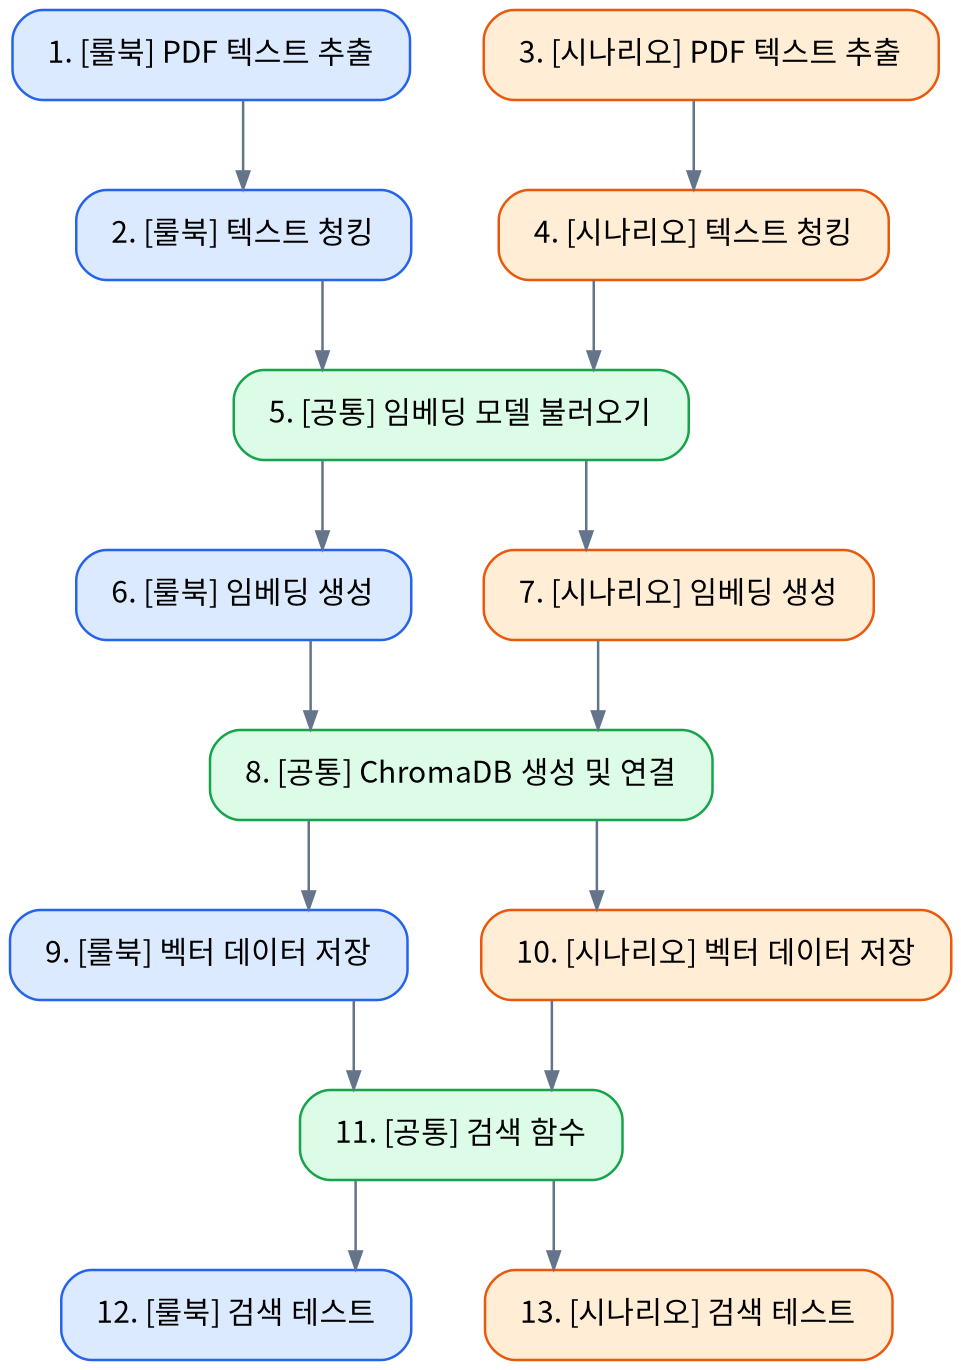

In [6]:
# 작업 순서 한눈에 보기편하게

# 1. 필요한 라이브러리 설치
!apt-get -qq install -y graphviz fonts-noto-cjk
!pip -q install graphviz

# 2. 라이브러리 불러오기
from graphviz import Digraph
from IPython.display import display, Image

# 3. 흐름도 생성
dot = Digraph("RAG_Workflow", format="png")

dot.attr(
    rankdir="TB",
    splines="ortho",
    nodesep="0.4",
    ranksep="0.5",
    dpi="180",
    bgcolor="white"
)

dot.attr(
    "node",
    shape="box",
    style="rounded,filled",
    fontname="Noto Sans CJK KR",
    fontsize="12",
    margin="0.2,0.12"
)

dot.attr(
    "edge",
    color="#64748b",
    arrowsize="0.7"
)

# 룰북 작업
dot.node("A", "1. [룰북] PDF 텍스트 추출",
         fillcolor="#dbeafe", color="#2563eb")
dot.node("B", "2. [룰북] 텍스트 청킹",
         fillcolor="#dbeafe", color="#2563eb")

# 시나리오 작업
dot.node("C", "3. [시나리오] PDF 텍스트 추출",
         fillcolor="#ffedd5", color="#ea580c")
dot.node("D", "4. [시나리오] 텍스트 청킹",
         fillcolor="#ffedd5", color="#ea580c")

# 공통 작업
dot.node("E", "5. [공통] 임베딩 모델 불러오기",
         fillcolor="#dcfce7", color="#16a34a")

dot.node("F", "6. [룰북] 임베딩 생성",
         fillcolor="#dbeafe", color="#2563eb")
dot.node("G", "7. [시나리오] 임베딩 생성",
         fillcolor="#ffedd5", color="#ea580c")

dot.node("H", "8. [공통] ChromaDB 생성 및 연결",
         fillcolor="#dcfce7", color="#16a34a")

dot.node("I", "9. [룰북] 벡터 데이터 저장",
         fillcolor="#dbeafe", color="#2563eb")
dot.node("J", "10. [시나리오] 벡터 데이터 저장",
         fillcolor="#ffedd5", color="#ea580c")

dot.node("K", "11. [공통] 검색 함수",
         fillcolor="#dcfce7", color="#16a34a")

dot.node("L", "12. [룰북] 검색 테스트",
         fillcolor="#dbeafe", color="#2563eb")
dot.node("M", "13. [시나리오] 검색 테스트",
         fillcolor="#ffedd5", color="#ea580c")

# 연결
dot.edge("A", "B")
dot.edge("C", "D")

dot.edge("B", "E")
dot.edge("D", "E")

dot.edge("E", "F")
dot.edge("E", "G")

dot.edge("F", "H")
dot.edge("G", "H")

dot.edge("H", "I")
dot.edge("H", "J")

dot.edge("I", "K")
dot.edge("J", "K")

dot.edge("K", "L")
dot.edge("K", "M")

# 4. 이미지 저장 및 출력
output_path = dot.render(
    filename="/content/RAG_워크플로우",
    cleanup=True
)

display(Image(filename=output_path))

In [7]:
# CromaDB, pymupdf 설치
!pip -q install chromaDB pymupdf

In [11]:
# 2.[룰북] PDF파일 텍스트로 추출하기

import fitz

from google.colab import drive
drive.mount('/content/drive')
pdf_name = "/content/drive/MyDrive/TRPG/D&D 룰북.pdf"

# PDF에서 텍스트 추출
doc = fitz.open(pdf_name)

rulebook_pages = []
empty_pages = []

for page_no, page in enumerate(doc, start=1): # PDF를 각 페이지를 하나씩 처리
  text = page.get_text("text").strip()         # 그 페이지의 텍스트를 추출

  if text:
        rulebook_pages.append({
            "page": page_no,
            "text": text
        })
  else :
        empty_pages.append(page_no)

# 추출 결과 확인
print("PDF 전체 페이지 수:", len(doc))
print("텍스트가 추출된 페이지 수:", len(rulebook_pages))
print("텍스트가 없는 페이지 번호:", empty_pages[:30])

print("\n첫 번째 페이지 텍스트:")
print(rulebook_pages[0]["text"][:50] if rulebook_pages else "추출된 텍스트 없음")

doc.close() # PDF파일 닫는다

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PDF 전체 페이지 수: 179
텍스트가 추출된 페이지 수: 179
텍스트가 없는 페이지 번호: []

첫 번째 페이지 텍스트:
1
베이직 룰 한국어판 
BASIC RULES
D&D Basic Rules, Version


In [12]:
# 2-1 [룰북] PDF 텍스트를 Chunk로 나누기
# (룰북과 스토리북 구분을 위한 문서ID, 청크 나누기)
# (rulebook_chunk, rulebook_pages)

# chunk_text 정의
def chunk_text(text, chunk_size=500, overlap=100):
  chunks = []
  start = 0

  while start < len(text):
    end = start + chunk_size          # chunk_size가 500이면 end = 0~499
    chunks.append(text[start:end])    # 반복

    if end >= len(text):              # end가 전체 문서 길이보다 많으면 break
      break

    start = end - overlap             # 400 = 500 - 100 (overlap으로 0~499하면 400부터 시작)

  return chunks

rulebook_chunks = []

# 룰북 PDF의 문서 ID와 Chunk 개수 나누기
doc_id = "D&D 룰북"

for page in rulebook_pages:
  parts = chunk_text(
      page["text"],
      chunk_size=500,
      overlap=100
  )

  for i, part in enumerate(parts):
    rulebook_chunks.append({
        "chunk_id": f"{doc_id}-page-{page['page']}-chunk-{i}",
        "doc_id": doc_id,
        "page": page["page"],
        "text": part
    })

print("문서 ID:", doc_id)
print("Chunk 개수:", len(rulebook_chunks))

for chunk in rulebook_chunks[:2]:
  print(chunk)

문서 ID: D&D 룰북
Chunk 개수: 1169
{'chunk_id': 'D&D 룰북-page-1-chunk-0', 'doc_id': 'D&D 룰북', 'page': 1, 'text': '1\n베이직 룰 한국어판 \nBASIC RULES\nD&D Basic Rules, Version 1.0, Released November 2018\nCredits\nLead Designers: Jeremy Crawford, Mike Mearls, \nChristopher Perkins\nDesign Team: James Wyatt, Rodney Thompson, Robert J.  \nSchwalb, Peter Lee, Steve Townshend, Bruce R. Cordell\nManaging Editor: Jeremy Crawford\nEditing Team: Chris Sims, Michele Carter, Scott Fitzgerald Gray,  \nKim Mohan\nGraphic Designers: Bree Heiss, Emi Tanji\nInterior Illustrator: Jaime Jones, Richard Whitters\nAdditional Contributors: Matt Sern'}
{'chunk_id': 'D&D 룰북-page-1-chunk-1', 'doc_id': 'D&D 룰북', 'page': 1, 'text': 'ss, Emi Tanji\nInterior Illustrator: Jaime Jones, Richard Whitters\nAdditional Contributors: Matt Sernett, Chris Dupuis, Tom \nLaPille, Chris Tulach, Miranda Horner, Jennifer Clarke Wilkes, \nSteve Winter, Chris Youngs, Ben Petrisor, Tom Olsen\nProducer: Greg Bilsland\nProject Management: Neil Shi

In [14]:
# 2 [시나리오] PDF파일 텍스트로 추출하기

from google.colab import drive
drive.mount('/content/drive')
pdf_name = "/content/drive/MyDrive/TRPG/D&D 시나리오.pdf"

doc = fitz.open(pdf_name)

scenario_pages = []
empty_pages = []

for page_no, page in enumerate(doc, start=1):
  text = page.get_text("text").strip()

  if text:
    scenario_pages.append({
        "page": page_no,
        "text": text
    })
  else:
    empty_pages.append(page_no)

# 추출 결과 확인
print("PDF 전체 페이지 수:", len(doc))
print("텍스트가 추출된 페이지 수:", len(scenario_pages))
print("텍스트가 없는 페이지 번호:", empty_pages[:30])

print("\n첫 번째 페이지 텍스트:")
print(scenario_pages[0]["text"][:50] if scenario_pages else "추출된 텍스트 없음")

doc.close() # PDF파일 닫는다

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
PDF 전체 페이지 수: 34
텍스트가 추출된 페이지 수: 34
텍스트가 없는 페이지 번호: []

첫 번째 페이지 텍스트:
잠긴 종 The Drowned Bell
SRD 5.2 기반 던전 공략 시나리오 · 핫시트 


In [15]:
# 2-1 [시나리오] PDF 텍스트를 Chunk로 나누기
# (룰북과 스토리북 구분을 위한 문서ID, 청크 나누기)
# (scenario_chunk, scenario_pages)

# chunk_text 정의
def chunk_text(text, chunk_size=500, overlap=100):
  chunks = []
  start = 0

  while start < len(text):
    end = start + chunk_size          # chunk_size가 500이면 end = 0~499
    chunks.append(text[start:end])    # 반복

    if end >= len(text):              # end가 전체 문서 길이보다 많으면 break
      break

    start = end - overlap             # 400 = 500 - 100 (overlap으로 0~499하면 400부터 시작)

  return chunks

scenario_chunks = []

# 룰북 PDF의 문서 ID와 Chunk 개수 나누기
doc_id = "D&D 시나리오"

for page in scenario_pages:
  parts = chunk_text(
      page["text"],
      chunk_size=500,
      overlap=100
  )

  for i, part in enumerate(parts):
    scenario_chunks.append({
        "chunk_id": f"{doc_id}-page-{page['page']}-chunk-{i}",
        "doc_id": doc_id,
        "page": page["page"],
        "text": part
    })

print("문서 ID:", doc_id)
print("Chunk 개수:", len(scenario_chunks))

for chunk in scenario_chunks[:2]:
  print(chunk)

문서 ID: D&D 시나리오
Chunk 개수: 101
{'chunk_id': 'D&D 시나리오-page-1-chunk-0', 'doc_id': 'D&D 시나리오', 'page': 1, 'text': '잠긴 종 The Drowned Bell\nSRD 5.2 기반 던전 공략 시나리오 · 핫시트 2~4인 · 1~3레벨 파티 · 장면 6개\nGM(진행자) 전용 문서입니다. 비밀과 결말이 그대로 적혀 있어 플레이어에게 공유하면 안 됩니다.\nTRPG 마스터봇의 시나리오 RAG 데이터(scenario.jsonl)에서 자동으로 만든 문서입니다.\n166\n문서\n27\n방\n6\n장면\n20\n선택 flag\n5\n함정\n33\n직업 전용 문서\n목차\n1. 줄거리\n2. 던전 구조 — 방 지도\n3. 한눈에 보는 구성\n4. 장면 1 · 에코 타운\n5. 장면 2 · 마른 우물과 수직 갱도\n6. 장면 3 · 수몰된 회랑\n7. 장면 4 · 필사실\n8. 장면 5 · 종실\n9. 장면 6 · 종루 꼭대기\n줄거리\n국경 마을 에코 타운의 우물이 마르고, 밤마다 땅 밑에서 종소리가 들린다. 마을은 종과 죽은 수도사들의\n저주를 의심한다. 사실은 반대다. 수백 년 전 묻힌 수도원에서 후계 수도사 일곱이 최근까지 8시간마다 종\n을 치며 봉인을 '}
{'chunk_id': 'D&D 시나리오-page-1-chunk-1', 'doc_id': 'D&D 시나리오', 'page': 1, 'text': "땅 밑에서 종소리가 들린다. 마을은 종과 죽은 수도사들의\n저주를 의심한다. 사실은 반대다. 수백 년 전 묻힌 수도원에서 후계 수도사 일곱이 최근까지 8시간마다 종\n을 치며 봉인을 지켜 왔다. 종은 경보가 아니라 봉인 장치다. 반년 전 촌장 할빅이 우물을 되살리려 수맥\n을 뚫었고, 물이 종실로 쏟아져 종이 잠겼다. 갇힌 수도사들은 41일 동안 구조 신호를 쳤고, 할빅은 우물\n가에서 그 소리를 듣고도 밧줄을 내리지 않았다. 봉인은 그때부터 갱신에 실패하고 있고, 실종자 셋은 일\n그

# 2 [룰북], [시나리오] 텍스트 추출 완료

# 2-1 [룰북], [시나리오] 청킹 완료

# 3 임베딩 모델로 청크 벡터화

In [25]:
# 3. 임베딩 모델 불러오기

# 1. 임베딩 모델 불러오기
!pip -q install sentence-transformers

from sentence_transformers import SentenceTransformer
import torch

한국어와 영어를 모두 처리하는 가벼운 모델
embedder = SentenceTransformer(
    "sentence-transformers/paraphrase-multilingual-MiniLM-L12-v2",
    device="cpu"
)
# 다른 임베딩 모델
# embedder = SentenceTransformer(
#     "BAAI/bge-m3",
#     device="cuda"
# )

print("임베딩 모델 준비 완료!")

modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/123 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/15.8k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/54.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/687 [00:00<?, ?B/s]

...

tokenizer.json: reconstructing file:   0%|          |  0.00B / 17.1MB            

tokenizer.json: downloading bytes:           |  0.00B            

special_tokens_map.json:   0%|          | 0.00/964 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/191 [00:00<?, ?B/s]

임베딩 모델 준비 완료!


In [26]:
# 3. [룰북 Test] 청킹한 룰북에서 일부만 Test

## 임시로 작성한 부분 실제로 룰북 RAG에서 청킹한 부분에서 원하는 조건을
## 잘 가져오는지 청크 500까지만 검색하고 가져오게 했음 테스트 결과는 애매함, 아직 크로마DB 저장 안 함
## RAG 문서 가져와서 토큰화 -> 청킹 -> 청킹된 자료에서 원하는 답변 얻는것까지는 우선 성공

# test_chunks = rulebook_chunks[:500]
rule_test_chunks = rulebook_chunks
texts = [chunk["text"] for chunk in rule_test_chunks]

embeddings = embedder.encode(
    texts,
    normalize_embeddings=True,
    show_progress_bar=True
)

print("임베딩 개수:", len(embeddings))
print("벡터 차원:", embeddings.shape)

# 3. 질문으로 검색 테스트
question = "전투 중 플레이어가 공격을 시도하면 명중 여부는 어떤 규칙으로 판정하는가?"

question_embedding = embedder.encode(
    [question],
    normalize_embeddings=True
)[0]

# 질문과 각 청크의 유사도 계산
similarities = embeddings @ question_embedding

# 유사도가 높은 상위 3개 출력
top_indices = similarities.argsort()[::-1][:3]

print("질문:", question)
for rank, idx in enumerate(top_indices, start=1):
    print(f"\n[{rank}위] 유사도: {similarities[idx]:.3f}")
    print(texts[idx][:100])

# D&D 룰북(영문판) 문제점
# 1. 한국어 질문에 대해 영어 룰북의 관련 규칙을 정확하게 검색하지 못하는 경우가 있음.
# 2. 룰북에 실제로 존재하는 규칙도 검색 결과 상위 3개에 포함되지 않는 경우가 있음.
# 3. 질문 표현이 원문과 유사할수록 검색 정확도가 높아지는 경향이 있음. (플레이어의 자유도가 떨어짐)
# 4. 자유 입력형 행동(예: 문을 발로 차서 부수기)에 대한 관련 규칙 검색 성능이 낮음.
# 5. 검색 유사도 점수가 높더라도 실제 질문과 관련 없는 청크가 검색되는 경우가 있음.

# D&D 룰북(번역판) 문제점
# 1. 정답 청크가 50위로 나옴, 검색 방식이 질문과 정답의 의미를 제대로 연결짓지 못하고 있음.
# 2. 청크값을 300, 500, 1500 오버랩 100, 200, 400 다양하게 시도해봄
# 3. 테스트 질문: 5개, 완전성공: 2개, 부분성공: 1개, 실패 2개, 현재 검증 성공률: 40%, 부분 성공 포함 시 60%
# 문서에 정답이 존재하는데도 다른 내용을 가져오는 이유는 RAG가 문서를 이해해서 정답을 찾는 게 아니라
# 질문과 비슷한 특징을 가진 청크를 점수로 비교해서 가져오기 때문.

# 결론 영문판, 번역판 둘 다 성능 개선 필요, 하이브리드 검색을 넣거나 임베딩 모델을 바꾸거나
# 룰북을 최소화시키거나(이건 웬만하면 안 건드는걸로))

Batches:   0%|          | 0/37 [00:00<?, ?it/s]

임베딩 개수: 1169
벡터 차원: (1169, 1024)
질문: 전투 중 플레이어가 공격을 시도하면 명중 여부는 어떤 규칙으로 판정하는가?

[1위] 유사도: 0.635
것이나 당신 중 원하는 목표에게 기회
공격을 가할 수 있습니다.
수중 전투
모험자들이 해저에 있는 고향으로 퇴각하는 사후아긴을 뒤쫓으
려 하거나, 고대의 난파선을 찾아 주변 상어와

[2위] 유사도: 0.630
과 민첩 내성 굴림에 
불리점을 받게 됩니다. 좁은 공간에 끼어있는 크리쳐를 목표로 하
는 명중 굴림은 이점을 받습니다.
전투 중의 행동
당신은 전투 도중 아래 주어진 행동들을 포

[3위] 유사도: 0.629
목표를 정합니다. 목
표는 크리쳐이거나 물체, 혹은 특정 지역일 수 있습니다.
2. 수정치 결정. DM은 목표가 엄폐를 받고 있는지 결정하고 목표
를 공격할 때 이점이나 불리점을 


In [20]:
sce_test_chunks = scenario_chunks
texts = [chunk["text"] for chunk in sce_test_chunks]

embeddings = embedder.encode(
    texts,
    normalize_embeddings=True,
    show_progress_bar=True
)

print("임베딩 개수:", len(embeddings))
print("벡터 차원:", embeddings.shape)

# 질문 검색 테스트
question = "에코 타운에서 발생하고 있는 이상 현상은 무엇이며, 그 원인은 무엇인가?"

question_embedding = embedder.encode(
    [question],
    normalize_embeddings=True
)[0]

# 질문과 각 청크의 유사도 계산
similarities = embeddings @ question_embedding

# 유사도가 높은 상위 3개 출력
top_indices = similarities.argsort()[::-1][:3]

print("시나리오 질문:", question)
for rank, idx in enumerate(top_indices, start=1):
  print(f"\n[{rank}위] 유사도: {similarities[idx]:.3f}")
  print(texts[idx][:100])

Batches:   0%|          | 0/4 [00:00<?, ?it/s]

임베딩 개수: 101
벡터 차원: (101, 384)
시나리오 질문: 에코 타운에서 발생하고 있는 이상 현상은 무엇이며, 그 원인은 무엇인가?

[1위] 유사도: 0.439
15가 필요하다.
대장간과 여관 village_market · 문서 6개
장면 묘사
전원
 scn-m-market-desc
대장간과 여관. 우물 광장 동쪽에 붙어 있는 두 건물이다

[2위] 유사도: 0.418
-rumor-bell
소문 — 종소리. 마을 사람들은 지하의 종이 사람을 불러 간다고 수군거린다. 실종자 셋이 밤마다 우
물 쪽으로
걸어간 것이 그 증거라고들 한다. 종소리가 들리

[3위] 유사도: 0.396
동안은 안전하고, 소리가 일그러지거나 멎으면 위험하다는 뜻이다.
일그러진 소리는 사람을 홀리고, 멎으면 봉인의 잔재가 풀려난다.
마을은 그 이유를 잊은 채 금기만 물려받았다 — 종


# 4 ChromaDB 생성

In [ ]:
# 4 ChromaDB 생성 및 PDF Chunk 등록

import chromadb

# Colab 로컬에 저장되는 ChromaDB
client = chromadb.PersistentClient(path="/content/drive/MyDrive/TRPG/chroma_pdf_db")

# 기존 컬렉션 완전히 삭제 (초기화)
# 예를 들어 청크값 500 오버랩 100으로 하다가
# 1000, 200으로 했을 때 이전 기록 초기화
try:
  client.delete_collection(name="pdf_chunk")
except:
  pass

# client : DB 전체.
# collection : ChromaDB 전용 객체.
# client.create_collection() : ChromaDB 안에 새로운 테이블(컬렉션)을
# 만들고, 벡터 검색 알고리즘과 거리 측정 기준을 설정함.
# hnsw(Hierarchical Navigable Small World) : 그래프 기반 근사 최근접
# 이웃(ANN) 인덱싱 알고리즘.
# metadata={...} : ChromaDB에게 "어떤 거리 계산 공식으로 벡터 간의
# '유사도'를 측정할 것인가"를 지시함.
# "cosine"으로 설정하면, '유사도'가 아니라 거리(distance)
# (=1-코사인유사도)가 반환됨. (0에 가까울수록 질문과 더 비슷한 문서!)
ion = client.create_collection(
    name="pdf_chunk", # 컬렉션의 고유 이름.
    metadata=["hnsw:space": "cosine"]
)

texts = [c["text"] for c in pdf_chunk]

# 문장임베딩 (texts의 순서가 embeddings에서도 그대로 유지됨.)
embeddings = embedder.encode(
    texts,
    normalize_embeddings=True
).tolist()
print(type(embeddings))

# ChromaDB에 등록.
collection.add(
    ids=[c["id"] for c in pdf_chunks],  # 문서 번호
    documents=texts,                    # 본문
    embeddings=embeddings,              # 벡터(임베딩)
    metadatas=[                         # 메타데이터
        {"page": c["page"], "source": pdf_name} for c in pdf_chunks
    ]
)

# collection.count() : 해당 테이블의 Chunk의 개수.
print("ChromaDB에 저장된 Chunk 개수:", collection.count())

# 작업 메모 — 다음 진행 사항
현재 완료
- GPU 테스트 및 Qwen 3.5 모델 로드·토큰화·응답 테스트
- 영문 D&D SRD 5.2 PDF 텍스트 추출 및 청킹
- 임베딩 모델로 전체 청크 벡터 변환
- 질문에 따른 유사도 검색 테스트 완료
현재 개선할 부분
1. 검색 일치도 개선: 청킹 방식과 임베딩 모델을 점검하고, 핵심 규칙이 상위 검색 결과에 나오도록 개선
2. 언어 방향 결정: 영문 룰북 유지 vs 한국어 번역본 사용 비교. 번역본은 라이선스와 번역 정확도 확인
3. 벡터 DB 연결: ChromaDB에 임베딩 벡터와 원문·페이지·문서 ID 등의 메타데이터 저장
4. 검색 성능 검증: 핵심 규칙 질문들을 정해 검색 결과의 정확도를 비교
다음 목표: 검색 일치도를 개선하고, 룰북 언어 방향을 결정한 뒤, ChromaDB에 벡터를 저장해 지속적으로 사용할 수 있게 만들기.